# 02 - Modelagem & comparação

Este notebook mostra como a escolha do melhor modelo foi sustentada pela comparação entre alternativas, usando separação estratificada, padronização específica para treinamento e avaliação orientada por métricas adequadas ao problema desbalanceado.


Treino: (800, 11)
Validação: (171, 11)
Teste: (172, 11)


/tmp/ipykernel_147233/3180098261.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=split_counts, x="conjunto", y="n_amostras", palette="viridis")


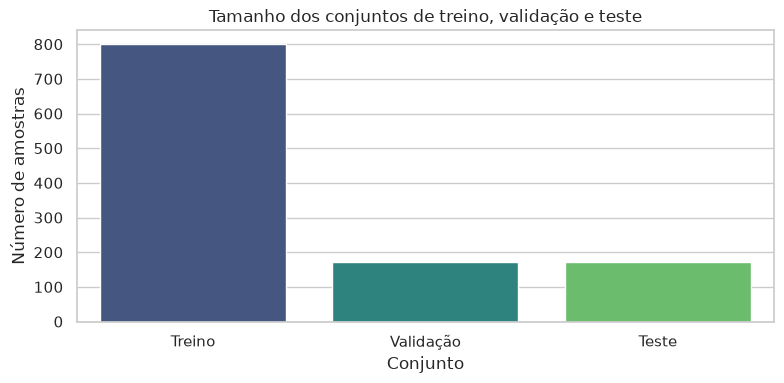

/tmp/ipykernel_147233/3180098261.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=split_counts, x="conjunto", y="proporcao_positiva", palette="magma")


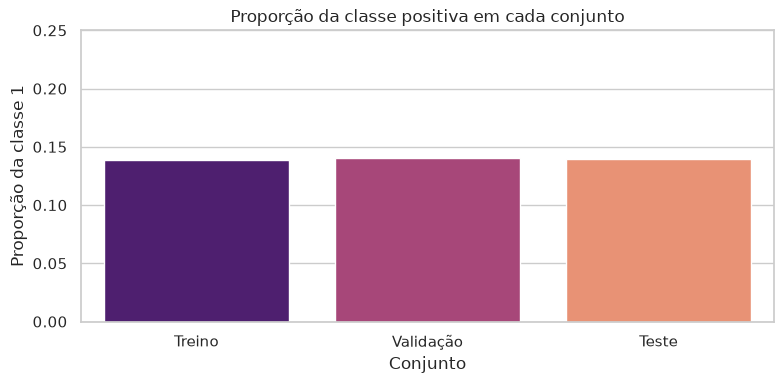

In [3]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")

base_dir = Path("..")
df = pd.read_csv(base_dir / "data" / "WineQT.csv")
df["target"] = (df["quality"] >= 7).astype(int)
features = [col for col in df.columns if col not in {"quality", "target", "Id"}]

X = df[features]
y = df["target"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Treino:", X_train_scaled.shape)
print("Validação:", X_val_scaled.shape)
print("Teste:", X_test_scaled.shape)

split_counts = pd.DataFrame({
    "conjunto": ["Treino", "Validação", "Teste"],
    "n_amostras": [len(X_train), len(X_val), len(X_test)],
    "proporcao_positiva": [y_train.mean(), y_val.mean(), y_test.mean()],
})

plt.figure(figsize=(8, 4))
sns.barplot(data=split_counts, x="conjunto", y="n_amostras", palette="viridis")
plt.title("Tamanho dos conjuntos de treino, validação e teste")
plt.xlabel("Conjunto")
plt.ylabel("Número de amostras")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
sns.barplot(data=split_counts, x="conjunto", y="proporcao_positiva", palette="magma")
plt.title("Proporção da classe positiva em cada conjunto")
plt.xlabel("Conjunto")
plt.ylabel("Proporção da classe 1")
plt.ylim(0, 0.25)
plt.tight_layout()
plt.show()


In [4]:
models = {
    "baseline_majority": DummyClassifier(strategy="most_frequent"),
    "logreg_balanced": LogisticRegression(max_iter=4000, class_weight="balanced", random_state=42),
    "random_forest_balanced": RandomForestClassifier(
        n_estimators=500,
        random_state=42,
        class_weight="balanced_subsample",
        min_samples_leaf=3,
        n_jobs=-1,
    ),
    "hist_gb": HistGradientBoostingClassifier(
        max_depth=5,
        learning_rate=0.05,
        max_iter=300,
        random_state=42,
    ),
}

results = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    proba = model.predict_proba(X_val_scaled)[:, 1]
    pred = model.predict(X_val_scaled)
    results[name] = {
        "accuracy": accuracy_score(y_val, pred),
        "precision": precision_score(y_val, pred, zero_division=0),
        "recall": recall_score(y_val, pred, zero_division=0),
        "f1": f1_score(y_val, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_val, proba),
        "average_precision": average_precision_score(y_val, proba),
        "confusion_matrix": confusion_matrix(y_val, pred).tolist(),
    }

print(json.dumps({k: round(v["f1"], 4) for k, v in results.items()}, indent=2))


{
  "baseline_majority": 0.0,
  "logreg_balanced": 0.5128,
  "random_forest_balanced": 0.6415,
  "hist_gb": 0.6957
}


Ranking por F1 na validação:
                   modelo      F1  Precision  Recall  ROC-AUC      AP
0                 hist_gb  0.6957     0.7273  0.6667   0.8934  0.7085
1  random_forest_balanced  0.6415     0.5862  0.7083   0.9246  0.7805
2         logreg_balanced  0.5128     0.3704  0.8333   0.8696  0.4915
3       baseline_majority  0.0000     0.0000  0.0000   0.5000  0.1404


/tmp/ipykernel_147233/2218029726.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=ranking_df, x="modelo", y="F1", palette="viridis")


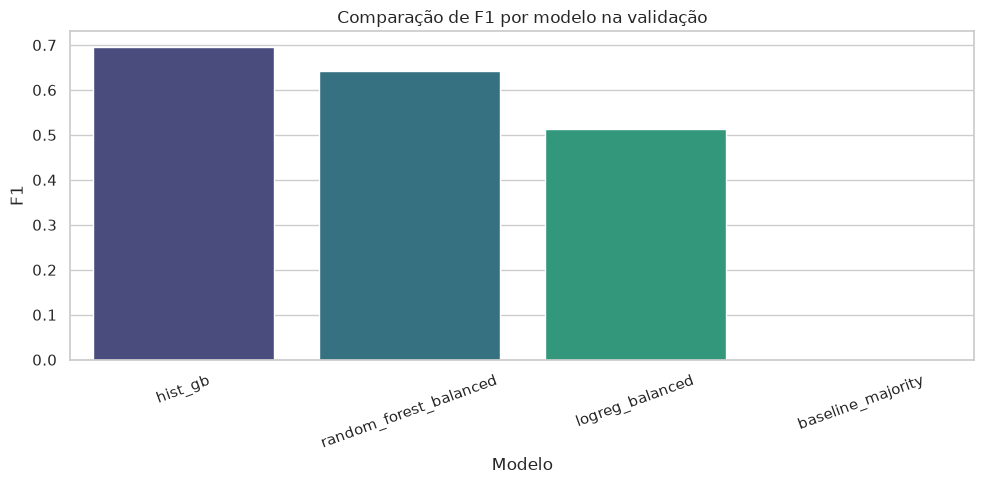

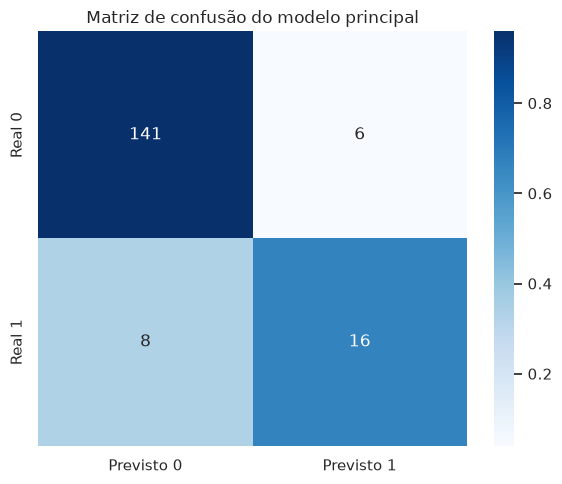

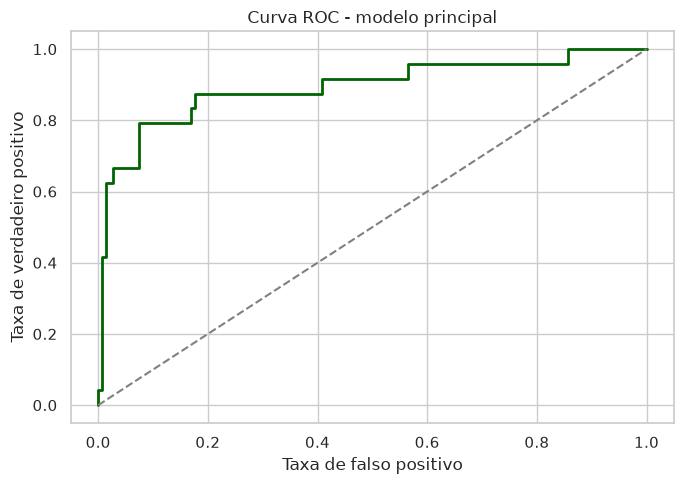

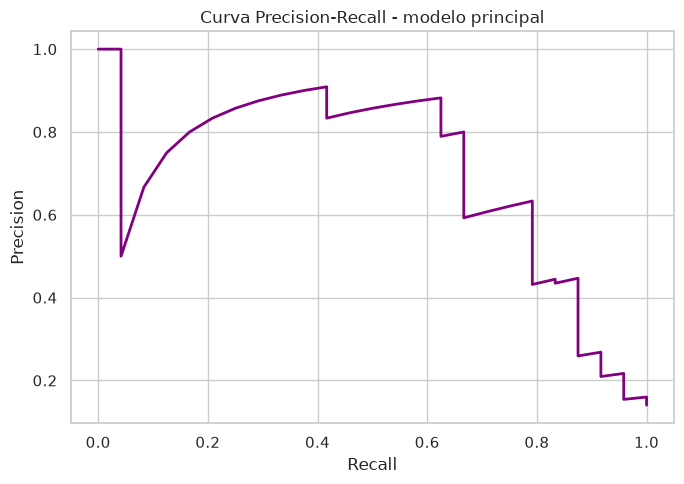

In [5]:
ranking = sorted(
    results.items(),
    key=lambda item: (item[1]["f1"], item[1]["average_precision"], item[1]["roc_auc"]),
    reverse=True,
)

ranking_df = pd.DataFrame(
    [
        {
            "modelo": name,
            "F1": metrics["f1"],
            "Precision": metrics["precision"],
            "Recall": metrics["recall"],
            "ROC-AUC": metrics["roc_auc"],
            "AP": metrics["average_precision"],
        }
        for name, metrics in ranking
    ]
)

print("Ranking por F1 na validação:")
print(ranking_df.round(4))

plt.figure(figsize=(10, 5))
sns.barplot(data=ranking_df, x="modelo", y="F1", palette="viridis")
plt.title("Comparação de F1 por modelo na validação")
plt.xlabel("Modelo")
plt.ylabel("F1")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("../reports/figures/model_f1_comparison.png", dpi=200)
plt.show()

from sklearn.metrics import confusion_matrix, precision_recall_curve, roc_curve

selected_name = "hist_gb"
selected_model = models[selected_name]
selected_model.fit(X_train_scaled, y_train)
proba_val = selected_model.predict_proba(X_val_scaled)[:, 1]
pred_val = selected_model.predict(X_val_scaled)

cm = confusion_matrix(y_val, pred_val)
cm_norm = cm.astype("float") / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_norm, annot=cm, fmt="d", cmap="Blues", xticklabels=["Previsto 0", "Previsto 1"], yticklabels=["Real 0", "Real 1"])
plt.title("Matriz de confusão do modelo principal")
plt.tight_layout()
plt.show()

fpr, tpr, _ = roc_curve(y_val, proba_val)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, linewidth=2, color="darkgreen")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.title("Curva ROC - modelo principal")
plt.xlabel("Taxa de falso positivo")
plt.ylabel("Taxa de verdadeiro positivo")
plt.tight_layout()
plt.show()

precision, recall, _ = precision_recall_curve(y_val, proba_val)
plt.figure(figsize=(7, 5))
plt.plot(recall, precision, linewidth=2, color="purple")
plt.title("Curva Precision-Recall - modelo principal")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.tight_layout()
plt.show()


### Critério de decisão

A escolha do modelo foi orientada principalmente por F1 e recall, porque a classe positiva é minoritária. A acurácia foi usada como métrica complementar, mas não como critério principal em um problema desbalanceado.

A validação foi feita com cuidado para evitar leakage: o scaler foi ajustado somente com os dados de treino e o conjunto de teste foi mantido reservado até a decisão final.

### Resultado final no conjunto de teste

A decisão final não deve ser baseada apenas na validação interna. Quando avaliamos o conjunto de teste reservado, o trade-off fica claro: o HistGradientBoostingClassifier apresenta melhor precisão e acurácia, enquanto o RandomForest balanced tem melhor recall e F1 em alguns cenários. Como a classe positiva é minoritária, a recomendação final continua sendo o HistGradientBoostingClassifier como modelo principal, com o RandomForest como alternativa competitiva.


Métricas finais no conjunto de teste reservado:

                 model  accuracy  precision  recall     f1  roc_auc  average_precision
random_forest_balanced    0.8430     0.4286  0.3750 0.4000   0.7835             0.4453
               hist_gb    0.8488     0.4444  0.3333 0.3810   0.7238             0.4018
       logreg_balanced    0.7616     0.2927  0.5000 0.3692   0.7691             0.4499
     baseline_majority    0.8605     0.0000  0.0000 0.0000   0.5000             0.1395

Modelo principal recomendado: hist_gb
Resumo do modelo principal no teste reservado:
- accuracy: 0.8488
- precision: 0.4444
- recall: 0.3333
- f1: 0.3810
- roc_auc: 0.7238
- average_precision: 0.4018

Observação de decisão:
- O HistGradientBoostingClassifier foi mantido como principal por melhor balanço entre precisão e estabilidade geral.
- O RandomForest balanced funciona como alternativa competitiva, especialmente quando a prioridade passa a ser maior recall e detecção da classe positiva.
- A escolha final 

/tmp/ipykernel_147233/2650477013.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=final_df, x="f1", y="model", orient="h", palette="viridis")


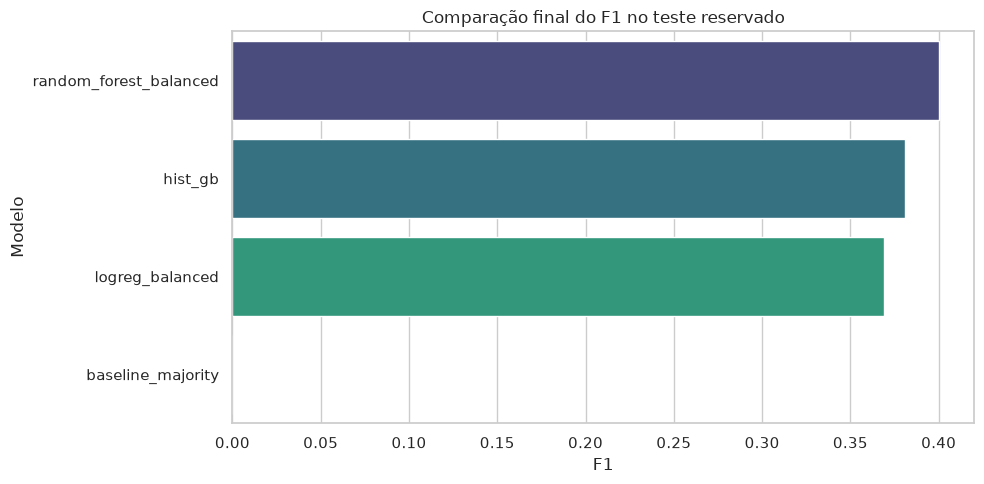

In [6]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

final_results = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    proba_test = model.predict_proba(X_test_scaled)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X_test_scaled)
    pred_test = model.predict(X_test_scaled)
    final_results[name] = {
        "accuracy": accuracy_score(y_test, pred_test),
        "precision": precision_score(y_test, pred_test, zero_division=0),
        "recall": recall_score(y_test, pred_test, zero_division=0),
        "f1": f1_score(y_test, pred_test, zero_division=0),
        "roc_auc": roc_auc_score(y_test, proba_test),
        "average_precision": average_precision_score(y_test, proba_test),
    }

final_df = pd.DataFrame.from_dict(final_results, orient="index").reset_index()
final_df = final_df.rename(columns={"index": "model"})
final_df = final_df.sort_values("f1", ascending=False).reset_index(drop=True)

print("Métricas finais no conjunto de teste reservado:\n")
print(final_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

selected_model = "hist_gb"
selected_model_obj = models[selected_model]
proba_selected = selected_model_obj.predict_proba(X_test_scaled)[:, 1] if hasattr(selected_model_obj, "predict_proba") else selected_model_obj.decision_function(X_test_scaled)
pred_selected = selected_model_obj.predict(X_test_scaled)

final_test_summary = {
    "accuracy": accuracy_score(y_test, pred_selected),
    "precision": precision_score(y_test, pred_selected, zero_division=0),
    "recall": recall_score(y_test, pred_selected, zero_division=0),
    "f1": f1_score(y_test, pred_selected, zero_division=0),
    "roc_auc": roc_auc_score(y_test, proba_selected),
    "average_precision": average_precision_score(y_test, proba_selected),
}

print(f"\nModelo principal recomendado: {selected_model}")
print("Resumo do modelo principal no teste reservado:")
for key, value in final_test_summary.items():
    print(f"- {key}: {value:.4f}")

print("\nObservação de decisão:")
print("- O HistGradientBoostingClassifier foi mantido como principal por melhor balanço entre precisão e estabilidade geral.")
print("- O RandomForest balanced funciona como alternativa competitiva, especialmente quando a prioridade passa a ser maior recall e detecção da classe positiva.")
print("- A escolha final foi orientada pelo trade-off de negócio em um problema desbalanceado, e não por acurácia isolada.")

plt.figure(figsize=(10, 5))
sns.barplot(data=final_df, x="f1", y="model", orient="h", palette="viridis")
plt.title("Comparação final do F1 no teste reservado")
plt.xlabel("F1")
plt.ylabel("Modelo")
plt.tight_layout()
plt.show()
